<!-- gs-watermark -->
> **© 2026 Gokaran Shukla** · part of [hopforge](https://github.com/Gokaran-Shukla/hopforge) · MIT License — any reuse must keep this copyright notice and credit the author.

# 05 · Berry phase, polarisation, Berry curvature and Chern numbers

$$\mathcal A_n=i\langle u_n|\nabla_{\mathbf k}u_n\rangle,\qquad
\Omega_n^{xy}=-2\,\mathrm{Im}\sum_{m\neq n}\frac{\langle n|v_x|m\rangle\langle m|v_y|n\rangle}{(E_n-E_m)^2},\qquad
C=\frac{1}{2\pi}\int_{BZ}\Omega^{xy}\,d^2k$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import hopforge as hf
M = hf.models
%matplotlib inline

## 1. Zak phase and polarisation of the SSH chain
Periodic gauge: quantised 0/π. Atomic gauge: includes orbital positions, so it gives the true Wannier centre.

In [2]:
for v, w in [(1.0, 0.5), (0.5, 1.0)]:
    s = M.ssh(v, w)
    print(f"v={v}, w={w}:  Zak(periodic) = {hf.zak_phase(s, gauge='periodic'):+.4f}   "
          f"P = {hf.polarization(s):.3f}   winding = {hf.winding_number(s, s.info['chiral']):+.0f}")

v=1.0, w=0.5:  Zak(periodic) = -0.0000   P = 0.750   winding = +0
v=0.5, w=1.0:  Zak(periodic) = -3.1416   P = 0.250   winding = -1


## 2. End states of an open SSH chain (bulk-boundary correspondence)

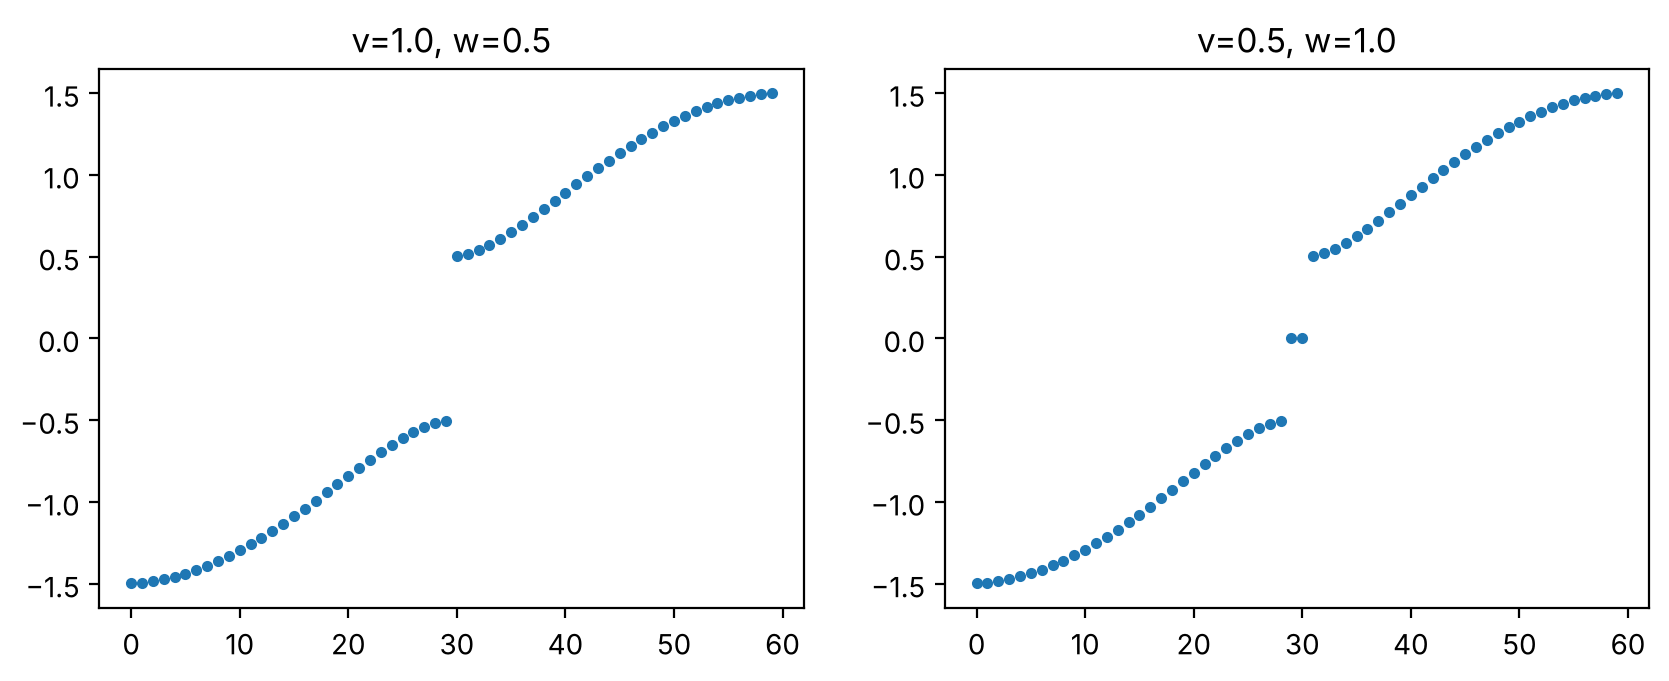

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, (v, w) in zip(axes, [(1.0, 0.5), (0.5, 1.0)]):
    E = M.ssh(v, w).finite(30).energies()
    ax.plot(E, "o", ms=3); ax.set_title(f"v={v}, w={w}")

## 3. Thouless pump in the Rice-Mele model
The polarisation changes by one unit per adiabatic cycle: the Chern number in $(k, t)$.

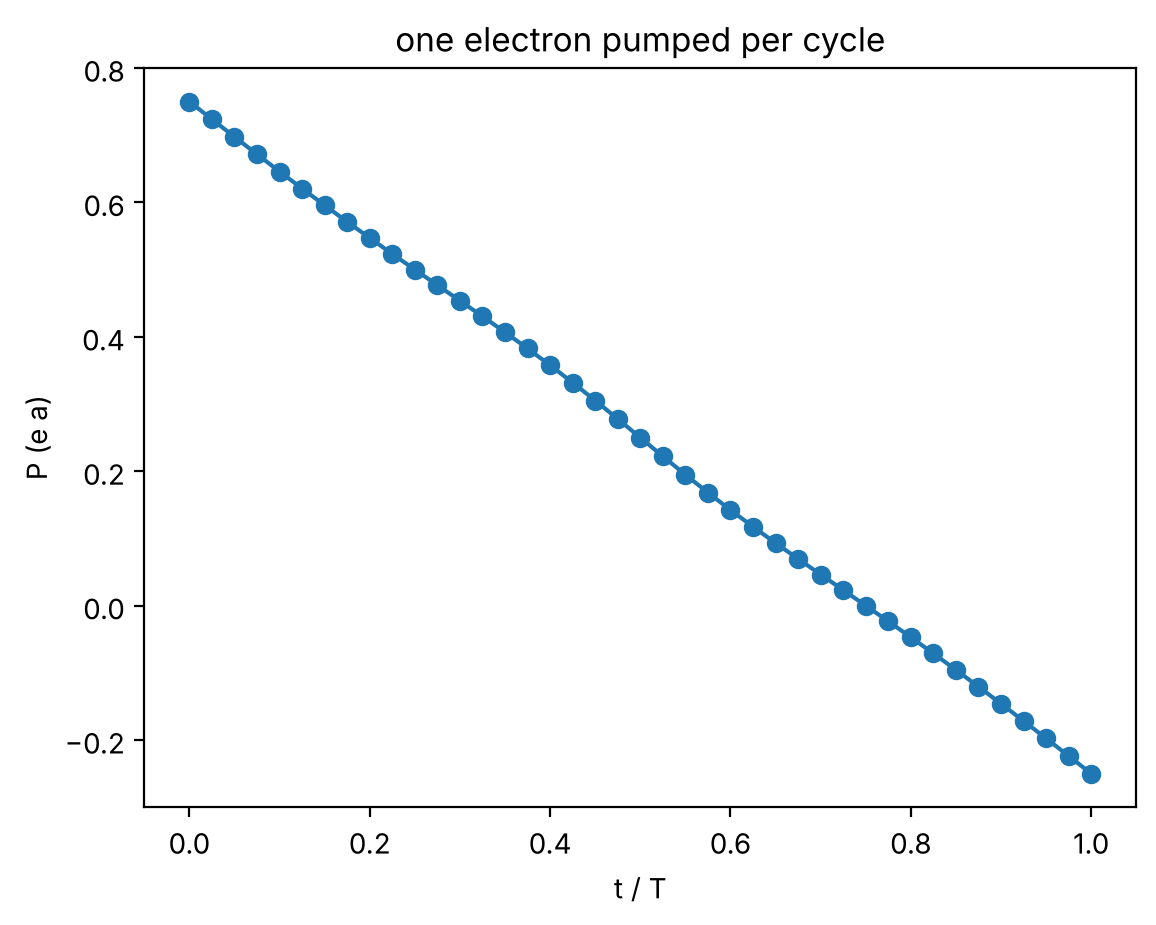

In [4]:
ts = np.linspace(0, 1, 41)
P = [hf.polarization(M.rice_mele(v=1 + 0.5*np.cos(2*np.pi*t), w=1.0, delta=0.5*np.sin(2*np.pi*t))) for t in ts]
plt.plot(ts, np.unwrap(np.array(P)*2*np.pi)/(2*np.pi), "o-"); plt.xlabel("t / T"); plt.ylabel("P (e a)");
plt.title("one electron pumped per cycle");

## 4. Berry curvature of the Haldane model

C (FHS) = 1.0    C (Kubo integral) = 0.9999999999999999


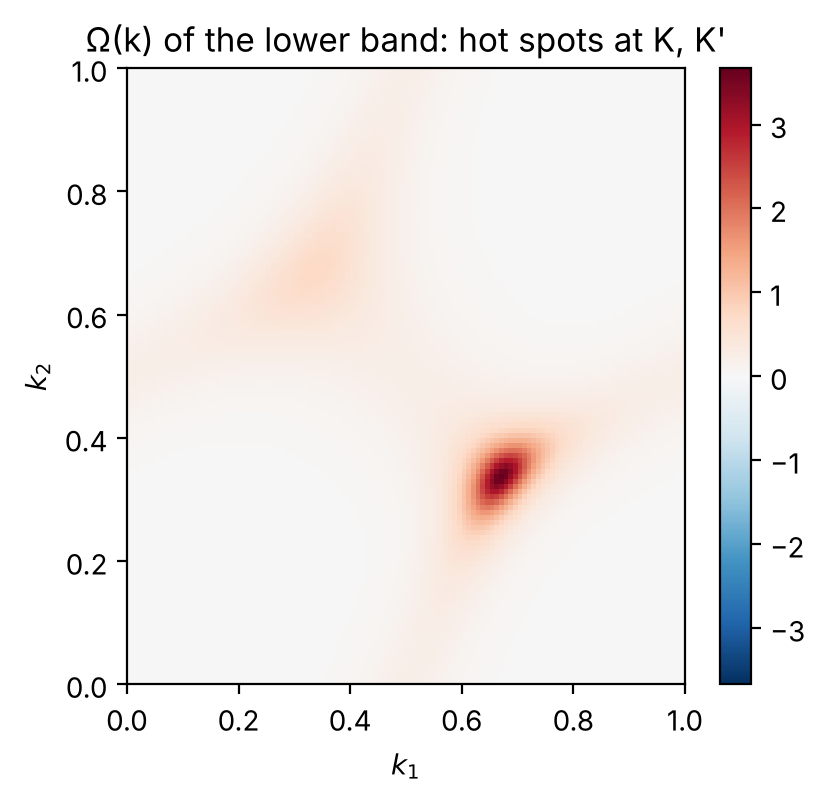

In [5]:
h = M.haldane(t2=0.1, M=0.2)
k1, k2, Om = hf.berry_curvature_map(h, occ=1, nk=120)
hf.plot_kmap(Om, title="Ω(k) of the lower band: hot spots at K, K'")
print("C (FHS) =", hf.chern_number(h, 1), "   C (Kubo integral) =", 2*np.pi*Om.mean()/h.lat.cell_volume)

## 5. Haldane phase diagram

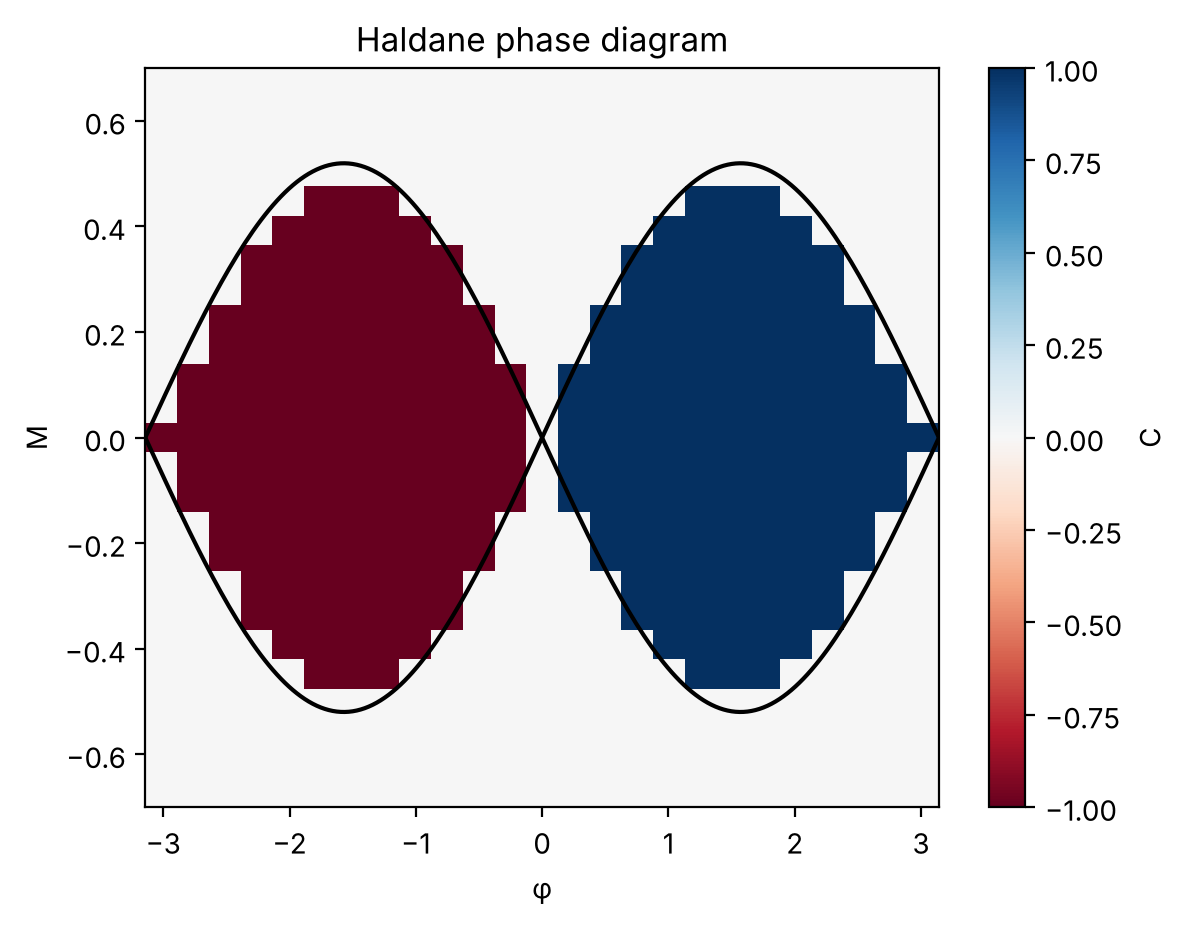

In [6]:
phis = np.linspace(-np.pi, np.pi, 25); Ms = np.linspace(-0.7, 0.7, 25)
C = np.array([[hf.chern_number(M.haldane(t2=0.1, phi=p, M=m), 1, 24) for p in phis] for m in Ms])
plt.imshow(np.round(C), origin="lower", extent=[-np.pi, np.pi, -0.7, 0.7], aspect="auto", cmap="RdBu")
pp = np.linspace(-np.pi, np.pi, 200)
plt.plot(pp, 3*np.sqrt(3)*0.1*np.sin(pp), "k"); plt.plot(pp, -3*np.sqrt(3)*0.1*np.sin(pp), "k")
plt.xlabel("φ"); plt.ylabel("M"); plt.colorbar(label="C"); plt.title("Haldane phase diagram");

## 6. QWZ Chern number versus mass

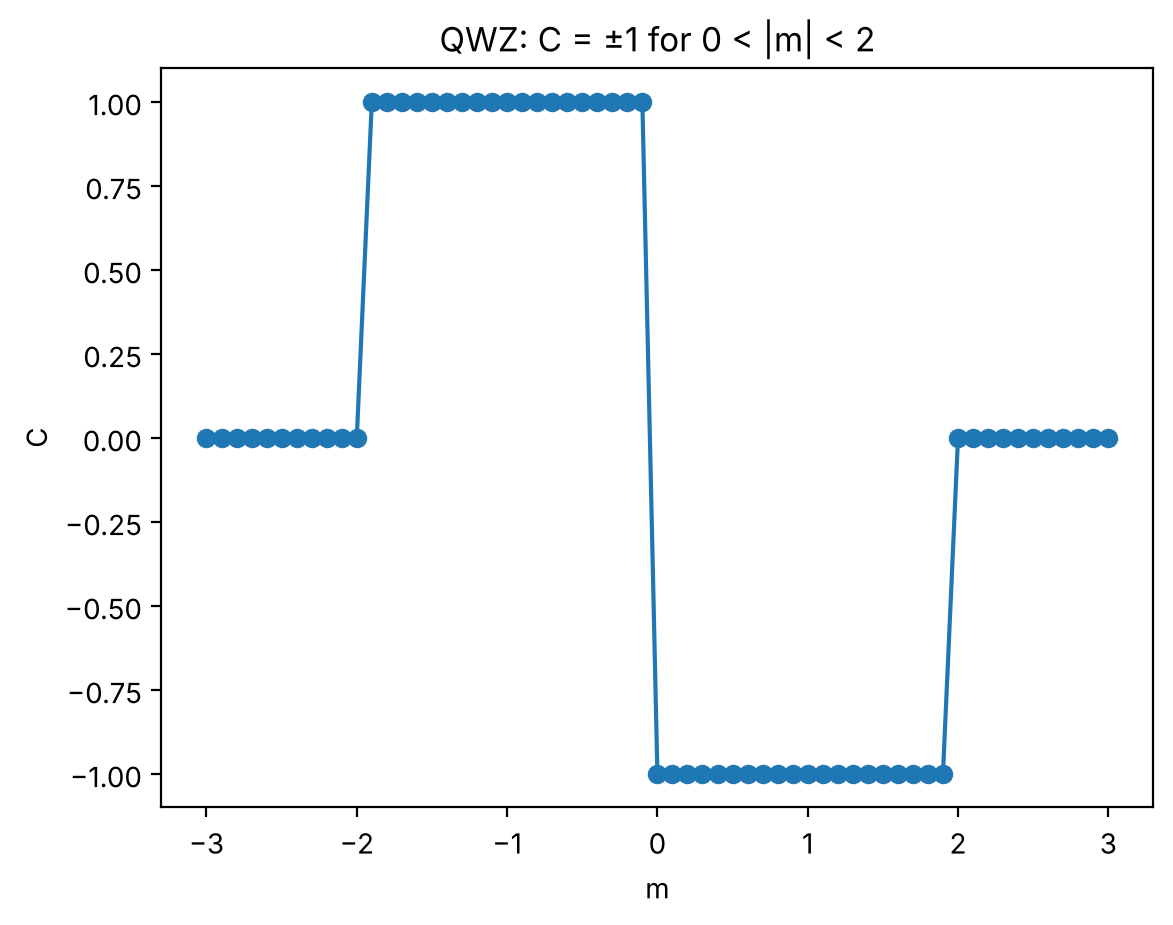

In [7]:
ms = np.linspace(-3, 3, 61)
plt.plot(ms, [hf.chern_number(M.qwz(m), 1, 30) for m in ms], "o-")
plt.xlabel("m"); plt.ylabel("C"); plt.title("QWZ: C = ±1 for 0 < |m| < 2");

## 7. Chern numbers of Hofstadter bands

In [8]:
for p, q in [(1, 3), (1, 4), (1, 5), (2, 5)]:
    m = M.hofstadter(p, q)
    print(f"flux {p}/{q}: C =", [round(hf.chern_number(m, [n], 40)) for n in range(q)])

flux 1/3: C = [1, -2, 1]
flux 1/4: C = [1, -1, -1, 1]
flux 1/5: C = [1, 1, -4, 1, 1]
flux 2/5: C = [-2, 3, -2, 3, -2]


## Exercises
1. Show numerically that the Berry curvature of gapped graphene (`M.honeycomb(delta=0.2)`) is opposite at K and K' (valley Hall), and that C = 0.
2. Compute the winding number of the Kitaev chain versus μ.
3. Check that the FHS Chern number converges already on a 10×10 mesh for the Haldane model.

---
## Quiz 05: Berry phase and Chern numbers

Twenty multiple-choice questions on this module. Run the next cell for a clickable
version (needs `ipywidgets`), or use the text version below it and grade yourself with
`quiz.check({1: 'a', 2: 'c', ...})`.

In [9]:
quiz = hf.Quiz(5)
quiz.interactive()

In [10]:
quiz.show()

=== Quiz 05: Berry phase, polarisation, Berry curvature and Chern numbers ===

Q1. The Berry connection of band n is
   (a) A_n = i <u_n | grad_k u_n>
   (b) A_n = <u_n|H|u_n>
   (c) A_n = |u_n|^2
   (d) A_n = grad_k E_n

Q2. A Berry phase is defined only modulo
   (a) 2 pi
   (b) 1
   (c) pi
   (d) 4 pi

Q3. In the periodic gauge, the Zak phase of the SSH chain is quantised to 0 or pi because of
   (a) inversion / chiral symmetry
   (b) particle-hole symmetry only
   (c) time reversal
   (d) translation

Q4. Polarisation in a 1D insulator (electron charge -e) is P = 
   (a) e Zak
   (b) 0 always
   (c) -e Zak / 2 pi (mod e a)
   (d) Zak / pi

Q5. Why does the atomic-gauge Zak phase of SSH give +-pi/2 rather than 0/pi?
   (a) spin-orbit coupling
   (b) a bug
   (c) it includes the intra-cell orbital positions (A at 0, B at 1/2)
   (d) the chain is metallic

Q6. Berry curvature Omega_n^{xy} from the Kubo formula involves
   (a) the DOS
   (b) the Fermi velocity
   (c) only band n
   (d)

In [11]:
my_answers = {
    1: '',
    2: '',
    3: '',
    4: '',
    5: '',
    6: '',
    7: '',
    8: '',
    9: '',
    10: '',
    11: '',
    12: '',
    13: '',
    14: '',
    15: '',
    16: '',
    17: '',
    18: '',
    19: '',
    20: '',
}
quiz.check(my_answers)

Q1: (no answer)
Q2: (no answer)
Q3: (no answer)
Q4: (no answer)
Q5: (no answer)
Q6: (no answer)
Q7: (no answer)
Q8: (no answer)
Q9: (no answer)
Q10: (no answer)
Q11: (no answer)
Q12: (no answer)
Q13: (no answer)
Q14: (no answer)
Q15: (no answer)
Q16: (no answer)
Q17: (no answer)
Q18: (no answer)
Q19: (no answer)
Q20: (no answer)

Score: 0 / 20


0